# 07 · Phân tích định lượng quy trình xử lý bug (Chương 2)

## 1. Mục tiêu và buổi học áp dụng

Trả lời **câu hỏi quản trị 2** (*thời gian đi đâu?*) và chuẩn bị số đo nền cho câu 4. Áp dụng **Buổi 2 — phân tích định lượng quy trình**: CT = PT + WT, hiệu suất chu trình CTE = PT/CT, định luật Little (L = λ·W), năng lực đo qua thông lượng, FPY (tỉ lệ đạt ngay lần đầu).

## 2. Đầu vào

Run `outputs/process/<run>` (bước A: `a_quant/`), cấu hình `configs/process.yaml`. Loader kiểm `status: completed`, sha256 từng artifact và `config_hash` trước khi đọc.

In [1]:
# Mở run giai đoạn 2 đã kiểm fingerprint. Không cần biến môi trường: nếu không chỉ định, tự chọn run
# hoàn tất mới nhất khớp configs/process.yaml hiện tại (bộ chạy `jira-ad notebooks` đặt JIRA_AD_PROCESS_RUN_DIR).
import pandas as pd
from IPython.display import Markdown, display

from jira_ad import process_plots as pp
from jira_ad.process_analysis import fmt, open_process_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
run = open_process_run()
print(run.header())

run: outputs/process/20261026T025412Z-399b0a40
chọn run: biến môi trường JIRA_AD_PROCESS_RUN_DIR
config: configs/process.yaml
config_hash: 399b0a40534a3d08466aaaf32175a68cb6d59cf4d90af65301ebb04c5e572a22
code.sha256: ed83115da72a96af6ecac17610d370d96a617635e4abc0c807ee7459ba84e9b6
tạo lúc (UTC): 2026-10-26T02:54:12.298067+00:00
số artifact đã kiểm sha256: 93


In [2]:
cfg = run.manifest["config"]
display(pd.DataFrame({"tham số": ["cohort", "trạng thái làm", "trạng thái chờ", "độ nhạy: làm",
                                  "ngưỡng cập nhật bù (giây)", "lịch chính"],
                      "giá trị": [", ".join(cfg["cohorts"]), ", ".join(cfg["states"]["work"]),
                                  ", ".join(cfg["states"]["wait"]), ", ".join(cfg["states"]["sensitivity_work"]),
                                  cfg["backfill"]["threshold_seconds"], cfg["calendar"]["primary"]]}))

,tham số,giá trị
0,cohort,"bug, story"
1,trạng thái làm,"In Progress, In Test"
2,trạng thái chờ,"Inbox, To Investigate, INVESTIGATED, To Do"
3,độ nhạy: làm,"To Investigate, In Progress, In Test"
4,ngưỡng cập nhật bù (giây),60.000
5,lịch chính,local


## 3. Dữ liệu và giả định

- **Jira chỉ ghi thời điểm đổi trạng thái**, không có thời điểm bắt đầu/kết thúc từng việc: PT là thời gian *nằm ở* trạng thái được xếp là "làm" (`In Progress`, `In Test` — Quyết định 2), WT là phần còn lại. Đây là **xấp xỉ**; vì vậy PT/WT/CTE được báo thành **khoảng** giữa bốn biến thể: {phân loại chính, `To Investigate` là làm} × {nguyên trạng, cận trên do cập nhật bù} (Ruling 68).
- **Cập nhật bù**: đổi trạng thái < 60 giây sau lần đổi trước được gắn cờ, không bị xóa.
- **Ngày làm việc** = T2–T6 theo giờ địa phương lấy từ offset gốc (−0700/−0800), chu kỳ 24 giờ, không ngày lễ (Quyết định 7, Ruling 70); UTC là độ nhạy.
- **Không có số nhân sự/giờ công**: năng lực chỉ đo qua thông lượng; phân tích nguồn lực dừng ở **vai trò**; `bot`, `unknown`, thiếu role không là nguồn lực.
- **Chỉ có ca đã đóng**: L = λ·W trên cả kỳ là đồng nhất thức; WIP cuối kỳ bị thiên lệch sống sót.

## 4. Kết quả

### 4.1 Bảng KPI AS-IS (bug; story đặt cạnh, không trộn)

In [3]:
kpi = {c: run.csv(f"a_quant/{c}/kpi_asis.csv").set_index("kpi") for c in cfg["cohorts"]}
table = pd.concat({c: k["value"] for c, k in kpi.items()}, axis=1)
table.insert(0, "đơn vị", kpi[cfg["cohorts"][0]]["unit"])
table.insert(1, "loại", kpi[cfg["cohorts"][0]]["kind"])
display(table)

,đơn vị,loại,bug,story
kpi,,,,
n_cases,ca,đo,161.000,182.000
share_done,tỉ lệ,đo,0.516,0.962
share_rejected,tỉ lệ,đo,0.484,0.038
ct_cal_median_days,ngày lịch,đo,23.032,27.278
ct_cal_p90_days,ngày lịch,đo,104.307,76.815
ct_work_median_days,ngày làm việc,đo,17.032,19.278
ct_work_p90_days,ngày làm việc,đo,74.307,54.815
pt_share_min,tỉ lệ,xấp xỉ (khoảng),0.167,0.280
pt_share_max,tỉ lệ,xấp xỉ (khoảng),0.592,0.319


### 4.2 PT, WT, CTE là một khoảng

pt_share                cte_median                 \
branch                   DONE Rejected   all       DONE Rejected   all   
variant                                                                  
main                    0.265    0.000 0.167      0.305    0.000 0.000   
main+backfill           0.422    0.008 0.269      0.504    0.000 0.045   
sensitivity             0.618    0.488 0.570      0.815    0.486 0.680   
sensitivity+backfill    0.648    0.497 0.592      0.860    0.602 0.739   

                     pt_median_days                 wt_median_days           \
branch                         DONE Rejected    all           DONE Rejected   
variant                                                                       
main                          6.161    0.000  0.000         15.650   13.432   
main+backfill                 8.369    0.000  0.794          8.838   13.432   
sensitivity                  15.819    6.291 10.067          3.980    4.052   
sensitivity+backfill         15.819    6.291 10.803          3.585    3.990   

                             
branch                  all  
variant                      
main                 15.060  
main+backfill        10.958  
sensitivity           3.998  
sensitivity+backfill  3.907

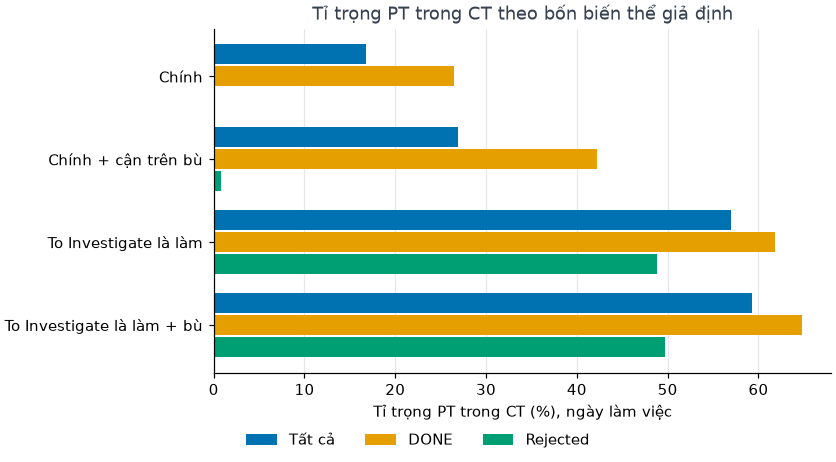

In [4]:
ranges = run.csv("a_quant/bug/pt_wt_ranges.csv")
display(ranges[ranges.clock == "work"].pivot(index="variant", columns="branch",
        values=["pt_share", "cte_median", "pt_median_days", "wt_median_days"]))
_ = run.show(pp.plot_pt_share_ranges(ranges, clock="work"))

### 4.3 Thời gian nằm ở từng trạng thái (dwell)

,state,state_class,n,n_cases,median,p75,p90,total_days
25,To Investigate,wait,114,106,10.876,27.860,41.337,2109.586
22,To Do,wait,106,90,0.003,7.755,47.409,1408.839
10,In Test,work,91,84,3.025,9.812,24.081,655.416
31,__CREATED__,created,161,161,1.952,3.958,7.971,504.261
4,INVESTIGATED,wait,114,106,0.163,2.186,4.680,284.508
7,In Progress,work,99,84,0.794,3.028,5.566,221.313
1,DONE,terminal,4,4,0.003,9.519,26.649,38.074
13,Inbox,wait,18,18,0.001,1.144,2.514,15.268
28,Triage,other,1,1,1.054,1.054,1.054,1.054
19,Rejected,terminal,5,5,0.000,0.002,0.043,0.072


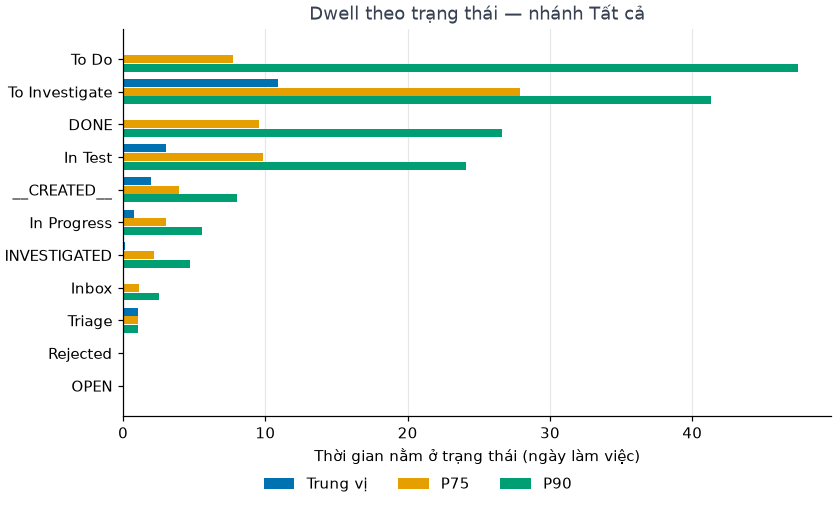

In [5]:
dwell = run.csv("a_quant/bug/dwell_by_state.csv")
view = dwell[(dwell.clock == "work") & (dwell.branch == "all")].sort_values("total_days", ascending=False)
display(view[["state", "state_class", "n", "n_cases", "median", "p75", "p90", "total_days"]])
_ = run.show(pp.plot_dwell_by_state(dwell, clock="work", branch="all"))

### 4.4 Định luật Little theo tuần

,giá trị
window_start,2021-06-02T07:24:19.359000+00:00
window_end,2022-06-27T08:58:53.987000+00:00
window_days,390.066
n_cases,161
lambda_per_day,0.413
W_days,45.625
L_measured,18.832
L_little,18.832
arrivals_first_half,109
arrivals_second_half,52


*Chỉ có ca đã đóng nên L = λ·W đúng theo định nghĩa trên cả cửa sổ; độ lệch theo tuần và giữa hai nửa kỳ mới mang thông tin về tính dừng.*

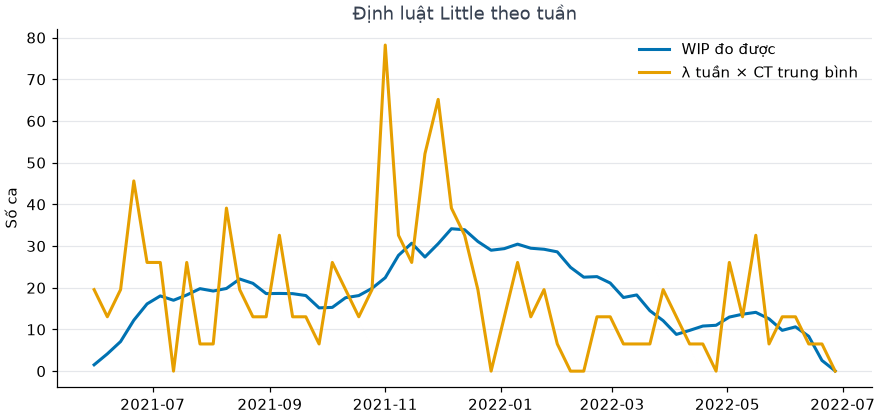

In [6]:
little = run.json("a_quant/bug/little.json")
display(pd.Series({k: v for k, v in little.items() if k != "note"}, name="giá trị").to_frame())
display(Markdown(f"*{little['note']}*"))
weeks = run.csv("a_quant/bug/weekly_little.csv")
_ = run.show(pp.plot_weekly_flow(weeks))

### 4.5 FPY và chi phí của nhánh Rejected

In [7]:
display(pd.Series(run.json("a_quant/bug/fpy.json"), name="giá trị").to_frame())
display(run.csv("a_quant/bug/rejected_cost.csv"))

,giá trị
n_cases,161
fpy_strict,0.814
fpy_adjusted,0.957
fpy_strict_done,0.759
fpy_adjusted_done,0.952
n_cases_rework,30
n_cases_rework_outside_backfill,7
definition,Lùi = sang trạng thái có thứ tự nhỏ hơn (states.order); mở lại = rời DONE/Rejected; adjusted bỏ ...


,group,n_cases,issue_days_cal,issue_days_work,median_days_cal,median_days_work
0,all,78,2713.834,1928.560,19.432,13.432
1,after_in_progress,1,60.916,42.916,60.916,42.916
2,before_in_progress,77,2652.918,1885.644,19.119,13.119


### 4.6 Vai trò cổng (ai chuyển ca vào trạng thái)

,target_state,role,n,share_of_target
0,DONE,SQA,47,0.540
5,INVESTIGATED,PO,23,0.202
8,In Progress,PO,38,0.384
12,In Test,Eng,45,0.495
15,Inbox,PO,13,0.722
20,OPEN,PO,1,1.000
21,Rejected,PO,73,0.880
25,To Do,PO,80,0.755
28,To Investigate,PO,104,0.912
33,Triage,PO,1,1.000


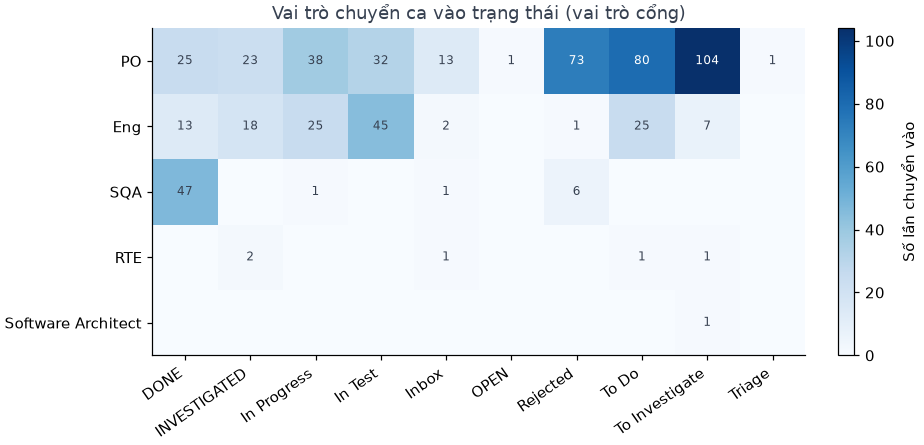

In [8]:
gates = run.csv("a_quant/bug/gate_roles.csv")
display(gates[gates.is_top_human][["target_state", "role", "n", "share_of_target"]])
_ = run.show(pp.plot_gate_roles(gates))

## 5. Quá trình nghiên cứu

- **Phân loại làm/chờ đã đổi theo quyết định của người dùng** (Quyết định 2): đề xuất ban đầu của agent xếp `To Investigate` là "làm"; phương án chính được duyệt xếp nó là hàng đợi và giữ đề xuất cũ làm độ nhạy bắt buộc. Bảng 4.2 cho thấy chính lựa chọn này quyết định phần lớn độ rộng của khoảng PT.
- **Cận trên do cập nhật bù** do agent định nghĩa (Ruling 68): lượt ngay trước một chuỗi chuyển nhanh có đi qua trạng thái "làm" được tính là làm.
- **Ngày làm việc theo offset gốc** của event mở lượt (Ruling 70); Little theo tuần UTC (Ruling 73); lượt ở trạng thái kết thúc giữa chừng tính là chờ (Ruling 74).
- **Kiểm đột biến** phát hiện hai lỗ hổng test (đổi sang chính trạng thái không phải "lùi"; lần đổi đầu sau CREATE không phải cập nhật bù) — đã khóa bằng test (Ruling 75).
- **Kiểm chéo độc lập** bằng pandas thô (không import `jira_ad`): số ca, số biến thể, số lần cập nhật bù và CT trung vị/P90 khớp pipeline (PROGRESS, Task 19).
- **Sau rà soát độc lập (Task 25)**: FPY adjusted đổi sang định nghĩa thống nhất "lần lùi/mở lại thuộc một đợt cập nhật bù" (kể cả lần đổi mở đầu đợt), cùng định nghĩa với bảng sai lệch ở notebook 09 (Ruling 106).

## 6. Nhận xét sinh từ số liệu

In [9]:
from jira_ad.process_analysis import remarks_quant

for cohort in cfg["cohorts"]:
    lines = "\n".join(f"- {line}" for line in remarks_quant(run, cohort))
    display(Markdown(f"**{cohort}**\n\n{lines}"))

**bug**

- 161 ca; CT trung vị 17,0 ngày làm việc (23,0 ngày lịch), P90 74,3 ngày làm việc; theo nhánh: DONE 28,7, Rejected 13,4.
- Tỉ trọng PT (ngày làm việc) dao động 16,7%–59,2% giữa bốn biến thể; phương án chính 16,7%, độ nhạy (To Investigate là làm) 57,0%; khoảng rộng 42,5 điểm % ⇒ kết luận PT/WT phụ thuộc cách xếp To Investigate.
- FPY strict 0,814, adjusted 0,957 (30 ca có lùi/mở lại, 7 ca nếu bỏ lần lùi trong đợt bù).
- 78 ca Rejected tiêu tốn 1.928,6 ngày-issue làm việc; 1 ca bị loại sau khi đã In Progress.
- Little: λ = 0,413 ca/ngày, W = 45,6 ngày, L = 18,8 ca (đồng nhất thức); ca đến nửa đầu/nửa sau kỳ: 109/52.
- Vai trò cổng: PO cho To Investigate (91%); PO cho To Do (75%); PO cho Rejected (88%); SQA cho DONE (54%).

**story**

- 182 ca; CT trung vị 19,3 ngày làm việc (27,3 ngày lịch), P90 54,8 ngày làm việc; theo nhánh: DONE 17,8, Rejected 41,8.
- Tỉ trọng PT (ngày làm việc) dao động 28,0%–31,9% giữa bốn biến thể; phương án chính 28,0%, độ nhạy (To Investigate là làm) 28,0%; khoảng hẹp 4,0 điểm % ⇒ PT/WT ổn định trước các giả định phân loại.
- FPY strict 0,945, adjusted 0,967 (10 ca có lùi/mở lại, 6 ca nếu bỏ lần lùi trong đợt bù).
- 7 ca Rejected tiêu tốn 352,1 ngày-issue làm việc; 2 ca bị loại sau khi đã In Progress.
- Little: λ = 0,482 ca/ngày, W = 36,0 ngày, L = 17,3 ca (đồng nhất thức); ca đến nửa đầu/nửa sau kỳ: 94/88.
- Vai trò cổng: Eng cho DONE (58%); PO cho To Do (56%); PO cho In Progress (15%); PO cho Rejected (78%).

## 7. Giả định, giới hạn, việc tiếp theo

- PT/WT là xấp xỉ; kết luận "thời gian đi đâu" chỉ bền ở các điểm không đổi giữa bốn biến thể.
- Story có ít ca Rejected nên các số Rejected của story không so được với bug.
- Việc tiếp theo: Chương 3 (notebook 08) đặt định mức và tìm trễ theo trạng thái/vai trò; Chương 4 dùng KPI AS-IS ở bảng 4.1 làm mốc so sánh cho TO-BE.